In [1]:
# ============================================================
# Notebook 09
# Adaptive Sensor Weight Generation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 120

In [2]:
# ============================================================
# Cell 2
# Load Camera and Sensor Confidence
# ============================================================

PROJECT_ROOT = Path(
    r"D:\Research\Papers\Paper_2"
)

RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR = PROJECT_ROOT / "figures"

DRIVE = "2011_09_26_drive_0001_sync"

# ------------------------------------------------------------
# Load Camera Confidence
# ------------------------------------------------------------

camera = pd.read_csv(

    RESULT_DIR /

    f"camera_confidence_{DRIVE}.csv"

)

# ------------------------------------------------------------
# Load GPS + IMU Sensor Confidence
# ------------------------------------------------------------

sensor = pd.read_csv(

    RESULT_DIR /

    f"sensor_confidence_index_{DRIVE}.csv"

)

print("=" * 70)

print("Datasets Loaded Successfully")

print("=" * 70)

print("Drive :", DRIVE)

print()

print("Camera Dataset Shape :", camera.shape)

print("Sensor Dataset Shape :", sensor.shape)

print("=" * 70)

display(camera.head())

display(sensor.head())

Datasets Loaded Successfully
Drive : 2011_09_26_drive_0001_sync

Camera Dataset Shape : (108, 10)
Sensor Dataset Shape : (108, 43)


,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence,Confidence Level
0,0.362415,0.824470,0.122920,0.256092,251,0.176659,0.870587,0,0.373539,Poor
1,0.282173,0.744032,0.107438,0.211880,250,0.181919,0.884934,1,0.338947,Poor
2,0.166911,0.716453,0.087152,0.162473,250,0.199297,0.904427,2,0.307125,Poor
3,0.191004,0.751561,0.086077,0.216606,252,0.232426,0.904300,3,0.331519,Poor
4,0.344544,0.817566,0.136863,0.364507,252,0.274970,0.849263,4,0.407605,Low


,lat,lon,alt,roll,pitch,yaw,vn,ve,vf,vl,...,GPS Heading Stability,Satellite Quality,Position Accuracy Score,Velocity Accuracy Score,Motion Smoothness,Angular Stability,GPS Confidence,IMU Confidence,Sensor Confidence Index,Confidence Level
0,49.015004,8.434297,116.430328,0.035752,0.009030,-2.608707,-6.811441,-11.275642,13.172717,-0.124753,...,0.997707,1.0,0.505047,0.716531,0.888550,0.995026,0.722199,0.941788,0.810035,High
1,49.014997,8.434280,116.432274,0.036453,0.008009,-2.611005,-6.769916,-11.250719,13.129880,-0.129612,...,0.997707,1.0,0.505047,0.716531,0.888550,0.995026,0.722199,0.941788,0.810035,High
2,49.014991,8.434265,116.435295,0.035908,0.006461,-2.613314,-6.731519,-11.221558,13.084994,-0.140397,...,0.997696,1.0,0.505047,0.716531,0.841668,0.996825,0.728720,0.919247,0.804930,High
3,49.014985,8.434249,116.440720,0.035565,0.005031,-2.615904,-6.684933,-11.198743,13.041455,-0.144497,...,0.997417,1.0,0.505047,0.716531,0.835807,0.999911,0.729196,0.917859,0.804661,High
4,49.014979,8.434233,116.447853,0.034299,0.006470,-2.618804,-6.634209,-11.175295,12.995313,-0.148616,...,0.997108,1.0,0.505047,0.716531,0.936416,0.998203,0.722257,0.967309,0.820278,High


In [3]:
assert len(camera) == len(sensor), \
    f"Camera={len(camera)}, Sensor={len(sensor)}"

camera = camera.reset_index(drop=True)

sensor = sensor.reset_index(drop=True)

N = len(camera)

print("=" * 60)
print("Camera Frames :", len(camera))
print("Sensor Frames :", len(sensor))
print("Total Frames  :", N)
print("=" * 60)

Camera Frames : 108
Sensor Frames : 108
Total Frames  : 108


In [4]:
fusion = pd.DataFrame({

"Frame":camera["Frame"],

"Camera Confidence":

camera["Camera Confidence"],

"GPS Confidence":

sensor["GPS Confidence"],

"IMU Confidence":

sensor["IMU Confidence"]

})

display(fusion.head())

,Frame,Camera Confidence,GPS Confidence,IMU Confidence
0,0,0.373539,0.722199,0.941788
1,1,0.338947,0.722199,0.941788
2,2,0.307125,0.728720,0.919247
3,3,0.331519,0.729196,0.917859
4,4,0.407605,0.722257,0.967309


In [5]:
columns=[

"Camera Confidence",

"GPS Confidence",

"IMU Confidence"

]

for column in columns:

    minimum=fusion[column].min()

    maximum=fusion[column].max()

    fusion[column]=(

        fusion[column]-minimum

    )/(

        (maximum-minimum+1e-8)

    )

display(fusion.head())

,Frame,Camera Confidence,GPS Confidence,IMU Confidence
0,0,0.195333,0.402966,0.716265
1,1,0.132514,0.402966,0.716265
2,2,0.074723,0.431558,0.603993
3,3,0.119024,0.433646,0.597081
4,4,0.257200,0.403218,0.843376


In [6]:
# ============================================================
# Temporal Confidence Stability
# ============================================================

WINDOW = 5

confidence_columns = [

    "Camera Confidence",

    "GPS Confidence",

    "IMU Confidence"

]

for column in confidence_columns:

    fusion[column + " Stability"] = (

        fusion[column]

        .rolling(

            WINDOW,

            min_periods=1

        )

        .std()

    )

    fusion[column + " Stability"] = (

        fusion[column + " Stability"]

        .fillna(0)

    )

display(fusion.head())

,Frame,Camera Confidence,GPS Confidence,IMU Confidence,Camera Confidence Stability,GPS Confidence Stability,IMU Confidence Stability
0,0,0.195333,0.402966,0.716265,0.000000,0.000000,0.000000
1,1,0.132514,0.402966,0.716265,0.044420,0.000000,0.000000
2,2,0.074723,0.431558,0.603993,0.060323,0.016508,0.064820
3,3,0.119024,0.433646,0.597081,0.049834,0.017132,0.066875
4,4,0.257200,0.403218,0.843376,0.071262,0.016204,0.100982


In [7]:
# ============================================================
# Reliability Estimation
# ============================================================

for column in confidence_columns:

    stability = fusion[column + " Stability"]

    stability_norm = (

        stability - stability.min()

    ) / (

        stability.max()-stability.min()+1e-8

    )

    fusion[column + " Reliability"] = (

        fusion[column]

        *

        (1 - stability_norm)

    )

display(fusion.head())

,Frame,Camera Confidence,GPS Confidence,IMU Confidence,Camera Confidence Stability,GPS Confidence Stability,IMU Confidence Stability,Camera Confidence Reliability,GPS Confidence Reliability,IMU Confidence Reliability
0,0,0.195333,0.402966,0.716265,0.000000,0.000000,0.000000,0.195333,0.402966,0.716265
1,1,0.132514,0.402966,0.716265,0.044420,0.000000,0.000000,0.105616,0.402966,0.716265
2,2,0.074723,0.431558,0.603993,0.060323,0.016508,0.064820,0.054125,0.416246,0.493813
3,3,0.119024,0.433646,0.597081,0.049834,0.017132,0.066875,0.091919,0.417678,0.484709
4,4,0.257200,0.403218,0.843376,0.071262,0.016204,0.100982,0.173443,0.389175,0.603699


In [8]:
# ============================================================
# Adaptive Dynamic Weight Generation
# ============================================================

total = (

      fusion["Camera Confidence Reliability"]

    + fusion["GPS Confidence Reliability"]

    + fusion["IMU Confidence Reliability"]

)

fusion["Camera Weight"] = (

    fusion["Camera Confidence Reliability"]

    / total

)

fusion["GPS Weight"] = (

    fusion["GPS Confidence Reliability"]

    / total

)

fusion["IMU Weight"] = (

    fusion["IMU Confidence Reliability"]

    / total

)

display(

fusion[[

"Camera Weight",

"GPS Weight",

"IMU Weight"

]].head()

)

,Camera Weight,GPS Weight,IMU Weight
0,0.148592,0.306539,0.544869
1,0.086228,0.328993,0.584779
2,0.056135,0.431708,0.512156
3,0.092445,0.420070,0.487484
4,0.148710,0.333678,0.517612


In [9]:
# ============================================================
# Weight Validation
# ============================================================

fusion["Weight Sum"] = (

      fusion["Camera Weight"]

    + fusion["GPS Weight"]

    + fusion["IMU Weight"]

)

display(

fusion[[

"Weight Sum"

]].head()

)

print("="*60)

print(

"Minimum Weight Sum :",

fusion["Weight Sum"].min()

)

print(

"Maximum Weight Sum :",

fusion["Weight Sum"].max()

)

print("="*60)

,Weight Sum
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0


Minimum Weight Sum : 0.9999999999999998
Maximum Weight Sum : 1.0000000000000002


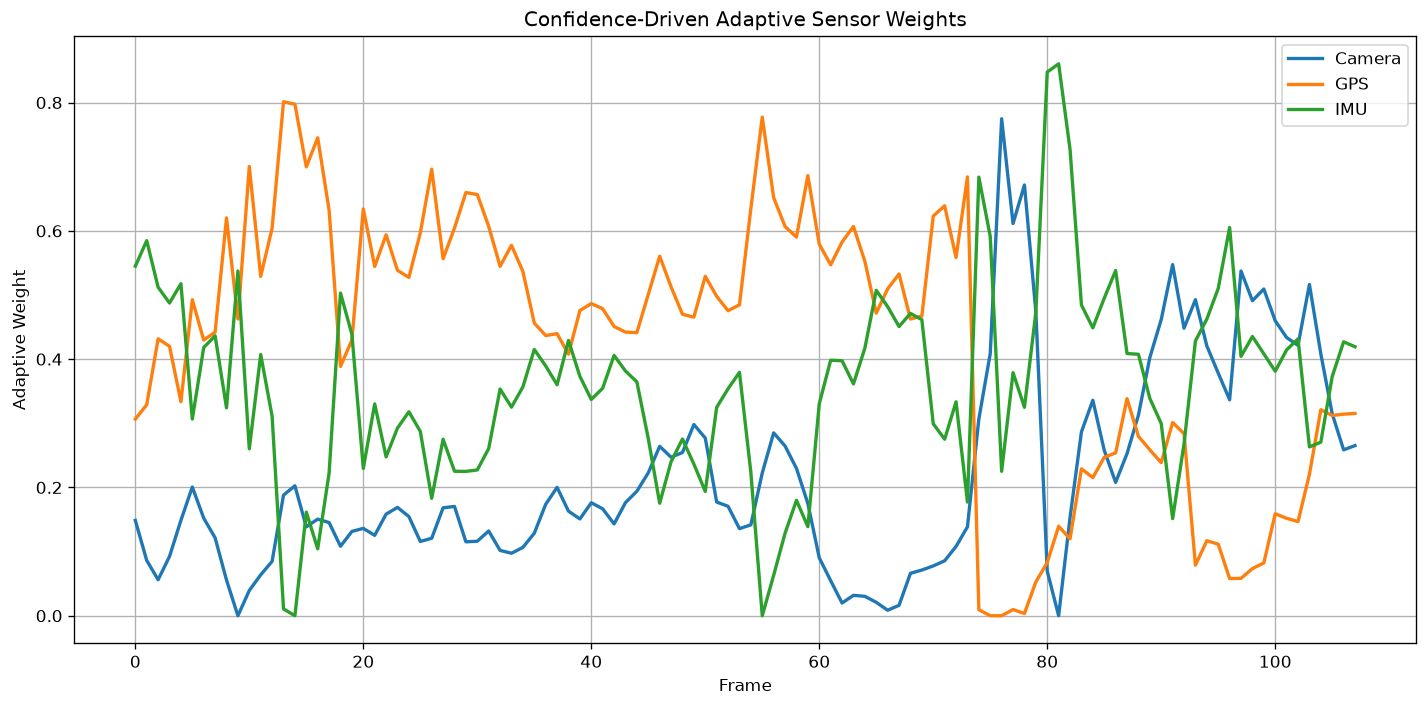

In [10]:
# ============================================================
# Dynamic Weight Evolution
# ============================================================

plt.figure(figsize=(12,6))

plt.plot(
    fusion["Frame"],
    fusion["Camera Weight"],
    linewidth=2,
    label="Camera"
)

plt.plot(
    fusion["Frame"],
    fusion["GPS Weight"],
    linewidth=2,
    label="GPS"
)

plt.plot(
    fusion["Frame"],
    fusion["IMU Weight"],
    linewidth=2,
    label="IMU"
)

plt.title("Confidence-Driven Adaptive Sensor Weights")

plt.xlabel("Frame")

plt.ylabel("Adaptive Weight")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "adaptive_sensor_weights.png",
    dpi=300
)

plt.show()

In [11]:
stats = fusion[[
    "Camera Weight",
    "GPS Weight",
    "IMU Weight"
]].describe()

display(stats)
stats.to_csv(

    RESULT_DIR /

    f"adaptive_weight_statistics_{DRIVE}.csv"

)

,Camera Weight,GPS Weight,IMU Weight
count,108.000000,108.000000,108.000000
mean,0.216575,0.424380,0.359045
std,0.158060,0.207270,0.151497
min,0.000000,0.000000,0.000000
25%,0.113503,0.282824,0.266719
50%,0.168581,0.468606,0.360754
75%,0.285453,0.580124,0.435613
max,0.774826,0.801296,0.860470


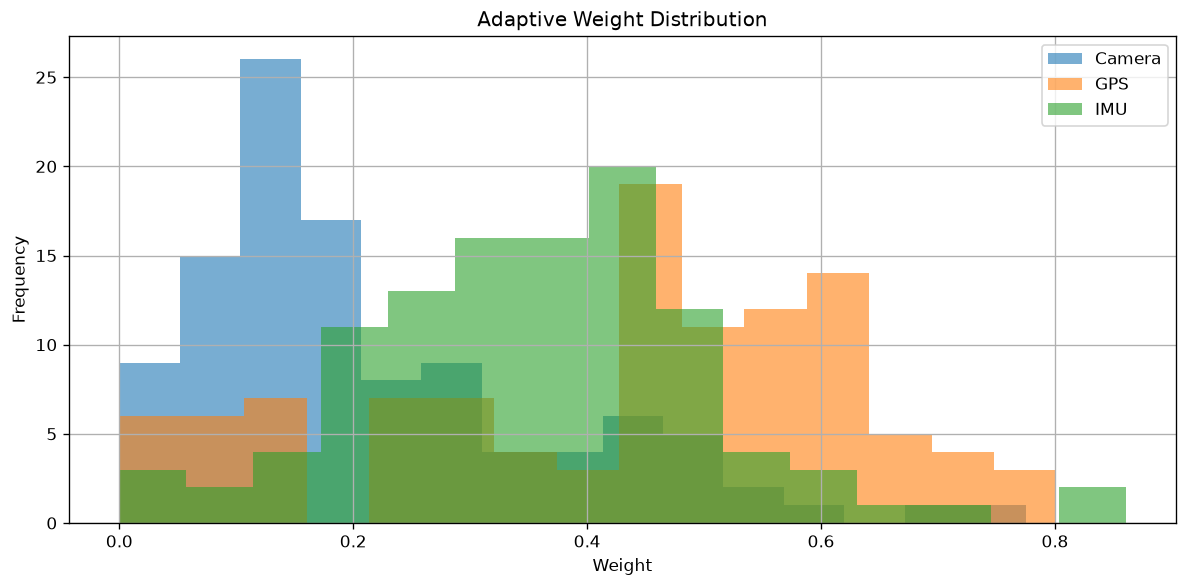

In [12]:
plt.figure(figsize=(10,5))

plt.hist(
    fusion["Camera Weight"],
    bins=15,
    alpha=0.6,
    label="Camera"
)

plt.hist(
    fusion["GPS Weight"],
    bins=15,
    alpha=0.6,
    label="GPS"
)

plt.hist(
    fusion["IMU Weight"],
    bins=15,
    alpha=0.6,
    label="IMU"
)

plt.legend()

plt.grid(True)

plt.title("Adaptive Weight Distribution")

plt.xlabel("Weight")

plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR/"adaptive_weight_distribution.png",
    dpi=300
)

plt.show()

In [13]:
fusion.to_csv(

    RESULT_DIR /

    f"adaptive_sensor_weights_{DRIVE}.csv",

    index=False

)

print("=" * 70)

print("Adaptive Sensor Weights Saved Successfully")

print("=" * 70)

Adaptive Sensor Weights Saved Successfully


In [14]:
print("=" * 80)

print("NOTEBOOK 09 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print()

print("Average Camera Weight :", round(fusion["Camera Weight"].mean(),3))

print("Average GPS Weight    :", round(fusion["GPS Weight"].mean(),3))

print("Average IMU Weight    :", round(fusion["IMU Weight"].mean(),3))

print()

print("Average Weight Sum    :", round(fusion["Weight Sum"].mean(),6))

print()

print("Generated Files")

print("----------------------------")

print(f"adaptive_sensor_weights_{DRIVE}.csv")

print(f"adaptive_weight_statistics_{DRIVE}.csv")

print()

print("Generated Figures")

print("----------------------------")

print("adaptive_weight_distribution.png")

print("READY FOR NOTEBOOK 10")

print("=" * 80)

NOTEBOOK 09 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync

Average Camera Weight : 0.217
Average GPS Weight    : 0.424
Average IMU Weight    : 0.359

Average Weight Sum    : 1.0

Generated Files
----------------------------
adaptive_sensor_weights_2011_09_26_drive_0001_sync.csv
adaptive_weight_statistics_2011_09_26_drive_0001_sync.csv

Generated Figures
----------------------------
adaptive_weight_distribution.png
READY FOR NOTEBOOK 10
